In [1]:
print("Welcome to House Price Prediction")
print("Machine Learning Project")

Welcome to House Price Prediction
Machine Learning Project


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [3]:
df = pd.read_csv("HousePrice.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (2919, 13)


In [4]:
df.head()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


In [5]:
print("Number of Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of Rows and Columns:
(2919, 13)

Column Names:
['Id', 'MSSubClass', 'MSZoning', 'LotArea', 'LotConfig', 'BldgType', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'Exterior1st', 'BsmtFinSF2', 'TotalBsmtSF', 'SalePrice']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Id            2919 non-null   int64  
 1   MSSubClass    2919 non-null   int64  
 2   MSZoning      2915 non-null   object 
 3   LotArea       2919 non-null   int64  
 4   LotConfig     2919 non-null   object 
 5   BldgType      2919 non-null   object 
 6   OverallCond   2919 non-null   int64  
 7   YearBuilt     2919 non-null   int64  
 8   YearRemodAdd  2919 non-null   int64  
 9   Exterior1st   2918 non-null   object 
 10  BsmtFinSF2    2918 non-null   float64
 11  TotalBsmtSF   2918 non-null   float64
 12  SalePrice     1460 non-null   float64
dt

In [9]:
selected_columns = [
    "LotArea",
    "OverallCond",
    "YearBuilt",
    "TotalBsmtSF",
    "SalePrice"
]

df[selected_columns].head()

,LotArea,OverallCond,YearBuilt,TotalBsmtSF,SalePrice
0,8450,5,2003,856.0,208500.0
1,9600,8,1976,1262.0,181500.0
2,11250,5,2001,920.0,223500.0
3,9550,5,1915,756.0,140000.0
4,14260,5,2000,1145.0,250000.0


In [8]:
print(df.columns.tolist())

['Id', 'MSSubClass', 'MSZoning', 'LotArea', 'LotConfig', 'BldgType', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'Exterior1st', 'BsmtFinSF2', 'TotalBsmtSF', 'SalePrice']


In [10]:
data = df[selected_columns].copy()

print("Missing Values:")
print(data.isnull().sum())

Missing Values:
LotArea           0
OverallCond       0
YearBuilt         0
TotalBsmtSF       1
SalePrice      1459
dtype: int64


In [11]:
data = data.dropna()

print("Dataset after removing missing values:")
print(data.shape)

Dataset after removing missing values:
(1460, 5)


In [12]:
X = data[
    ["LotArea", "OverallCond", "YearBuilt", "TotalBsmtSF"]
]

y = data["SalePrice"]

print("Input Data:")
print(X.head())

print("\nTarget Price:")
print(y.head())

Input Data:
   LotArea  OverallCond  YearBuilt  TotalBsmtSF
0     8450            5       2003        856.0
1     9600            8       1976       1262.0
2    11250            5       2001        920.0
3     9550            5       1915        756.0
4    14260            5       2000       1145.0

Target Price:
0    208500.0
1    181500.0
2    223500.0
3    140000.0
4    250000.0
Name: SalePrice, dtype: float64


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Rows:", len(X_train))
print("Testing Rows:", len(X_test))

Training Rows: 1168
Testing Rows: 292


In [14]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [15]:
y_pred = model.predict(X_test)

print("Actual House Prices:")
print(y_test.head().values)

print("\nPredicted House Prices:")
print(y_pred[:5])

Actual House Prices:
[154500. 325000. 115000. 159000. 315500.]

Predicted House Prices:
[196717.55596462 230427.00338433 134872.03515799 161713.35548008
 256197.01563324]


In [16]:
mae = mean_absolute_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 3))

Mean Absolute Error: 39827.33
R2 Score: 0.553


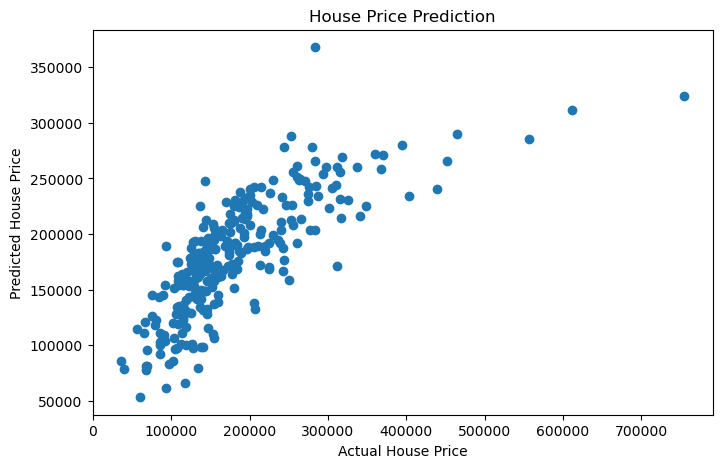

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.title("House Price Prediction")

plt.show()

In [18]:
lot_area = float(input("Enter plot area: "))
condition = int(input("Enter house condition (1-10): "))
year_built = int(input("Enter construction year: "))
basement_area = float(input("Enter basement area: "))

new_house = pd.DataFrame({
    "LotArea": [lot_area],
    "OverallCond": [condition],
    "YearBuilt": [year_built],
    "TotalBsmtSF": [basement_area]
})

predicted_price = model.predict(new_house)

print("\nPredicted House Sale Price: $", round(predicted_price[0], 2))

Enter plot area:  8000
Enter house condition (1-10):  5
Enter construction year:  2000
Enter basement area:  1000



Predicted House Sale Price: $ 197487.09
